# Etapa 43 — Política hierárquica final: validação, previsão operacional, plausibilidade, faixas e consolidação

Consolida a decisão das etapas 41–42 e refaz, para a nova política, o que as etapas 37–40 faziam para a anterior
(as pastas `etapa_37`–`etapa_40` permanecem como registro da política V2).

**Política final** (todos os horizontes reconciliados com MinT-OAS não negativo → coerente e sem negativos):

| Horizonte | Base | Brasil | Regiões | UFs |
|---|---|---|---|---|
| 1 e 4 | V3 | ETS amortecido | ETS amortecido | LightGBM Tweedie (só UFs) |
| 8 | V4 | ingênuo sazonal | LightGBM global | LightGBM global |
| 13 | V4 | ingênuo sazonal | ingênuo sazonal | LightGBM global |

Em h = 8 a Base V4 sem reconciliação tinha MASE um pouco menor em regiões/UFs, mas **não é coerente** (Brasil por
ingênuo sazonal ≠ soma das UFs por LightGBM). Coerência e não negatividade foram critérios operacionais da
etapa 37, por isso h = 8 também usa MinT — e ainda supera a política anterior nos três níveis.

Seções: 1) política e composição · 2) validação nas 58 origens · 3) previsão operacional (antiga etapa 38) ·
4) plausibilidade dos ajustes (38A) · 5) faixas empíricas com cobertura LOO (39) · 6) quadros finais (40).

In [1]:
import warnings

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display
from statsmodels.tools.sm_exceptions import ConvergenceWarning
from statsmodels.tsa.holtwinters import ExponentialSmoothing

# funções compartilhadas das etapas 41–43 (hierarquia, métricas, MinT, LightGBM)
from vsr_hier import (CHAVE, COLUNAS, HORIZONTES, ORDEM_NIVEL, ORDEM_NOS, REGIAO_DO_NO, RES, SEMANA, Y,
                      anexar_observado, carregar_candidatos, com_erros, compor_base, ler, metricas,
                      prever_lgbm_global, prever_lgbm_uf, reconciliar_longo, vetores_erro)

warnings.filterwarnings("ignore")
pd.set_option("display.width", 200)

DIR_SAIDA = RES / "etapa_43_politica_final"
DIR_SAIDA.mkdir(exist_ok=True)

## 1. Política final e composição das bases

In [2]:
CANDIDATOS = carregar_candidatos()
vencedores_v4 = ler("etapa_42_lgbm_global_vs_ets/vencedores_base_v4.csv")
COMPOSICAO = {
    "V3": {(n, h): ("LGBM_TWEEDIE_UF" if n == "UF" else "BASE_V2") for n in ORDEM_NIVEL for h in HORIZONTES},
    "V4": {(r.nivel, r.horizonte_semanas): r.vencedor for r in vencedores_v4.itertuples()},
}
POLITICA_FINAL = {1: "V3", 4: "V3", 8: "V4", 13: "V4"}  # base por horizonte; todas reconciliadas por MinT
ESTRATEGIA = {h: f"MINT_OAS_NAO_NEGATIVO_{b}" for h, b in POLITICA_FINAL.items()}


def escolha_do_horizonte(h):
    return {k: v for k, v in COMPOSICAO[POLITICA_FINAL[h]].items() if k[1] == h}


composicao = pd.DataFrame([{"horizonte_semanas": h, "base": b, **{n: escolha_do_horizonte(h)[(n, h)] for n in ORDEM_NIVEL}}
                           for h, b in POLITICA_FINAL.items()])
composicao.to_csv(DIR_SAIDA / "composicao_politica_final.csv", index=False)
display(composicao)

,horizonte_semanas,base,BRASIL,REGIAO,UF
0,1,V3,BASE_V2,BASE_V2,LGBM_TWEEDIE_UF
1,4,V3,BASE_V2,BASE_V2,LGBM_TWEEDIE_UF
2,8,V4,BASE_V2,LGBM_GLOBAL,LGBM_GLOBAL
3,13,V4,BASE_V2,BASE_V2,LGBM_GLOBAL


## 2. Validação da política final nas 58 origens formais
Erros de calibração do MinT vêm das mesmas bases nas 39 origens de calibração (2020-12-20 a 2021-09-12).

In [3]:
ERROS_CALIB, partes = {}, []
for h in HORIZONTES:
    base_formal = compor_base(CANDIDATOS, escolha_do_horizonte(h), "FORMAL")
    ERROS_CALIB[h] = vetores_erro(compor_base(CANDIDATOS, escolha_do_horizonte(h), "CALIBRACAO"))
    final, _ = reconciliar_longo(base_formal, ERROS_CALIB[h])
    partes.append(final.rename(columns={"previsao": "previsao_final"}).merge(
        base_formal[CHAVE + ["previsao", "modelo_base"]].rename(columns={"previsao": "previsao_base"}), on=CHAVE))
validacao = com_erros(pd.concat(partes, ignore_index=True), "previsao_final").assign(
    estrategia_final=lambda d: d["horizonte_semanas"].map(ESTRATEGIA),
    regiao=lambda d: (d["nivel"] + "_" + d["unidade"]).map(REGIAO_DO_NO))
assert len(validacao) == 58 * 4 * 33 and not validacao.duplicated(CHAVE).any()
validacao.to_csv(DIR_SAIDA / "previsoes_validacao_politica_final.csv", index=False)

metricas_final = metricas(validacao, ["nivel", "horizonte_semanas"], "previsao_final")
metricas_final.to_csv(DIR_SAIDA / "metricas_politica_final.csv", index=False)

# Auto-checagem: h=1/4 reproduzem a POLITICA_V3 da etapa 41 e h=13 a MINT_NN_V4 da etapa 42
ref = pd.concat([
    ler("etapa_41_modelos_intermitentes_ufs/comparacao_politica_v3_vs_atual.csv").query(
        "estrategia == 'POLITICA_V3' and horizonte_semanas in [1, 4]"),
    ler("etapa_42_lgbm_global_vs_ets/comparacao_politicas_atual_v3_v4.csv").query(
        "estrategia == 'MINT_NN_V4' and horizonte_semanas in [8, 13]"),
]).merge(metricas_final, on=["nivel", "horizonte_semanas"], suffixes=("_ref", ""))
assert len(ref) == 12 and np.allclose(ref["mase"], ref["mase_ref"]) and np.allclose(ref["mae"], ref["mae_ref"])

politica_v2 = ler("etapa_37_comparacao_final_hierarquica/previsoes_politica_hierarquica_proposta.csv")
base_v2 = CANDIDATOS["BASE_V2"]["FORMAL"]
referencias = {"base_v2": metricas(base_v2, ["nivel", "horizonte_semanas"]),
               "politica_v2": metricas(politica_v2, ["nivel", "horizonte_semanas"], "previsao_final"),
               "politica_final": metricas_final}
desempenho = None
for nome, df in referencias.items():
    df = df.set_index(["nivel", "horizonte_semanas"])[["mae", "rmse", "mase"]].add_suffix(f"_{nome}")
    desempenho = df if desempenho is None else desempenho.join(df)
desempenho = desempenho.reindex(ORDEM_NIVEL, level=0).reset_index()
for ref_nome in ("base_v2", "politica_v2"):
    desempenho[f"delta_mase_final_menos_{ref_nome}"] = desempenho["mase_politica_final"] - desempenho[f"mase_{ref_nome}"]
desempenho["leitura"] = np.select(
    [desempenho[["mase_base_v2", "mase_politica_v2"]].min(axis=1) > desempenho["mase_politica_final"]],
    ["POLITICA_FINAL_MELHOR"], "REFERENCIA_MELHOR")
display(desempenho.round(3))

,nivel,horizonte_semanas,mae_base_v2,rmse_base_v2,mase_base_v2,mae_politica_v2,rmse_politica_v2,mase_politica_v2,mae_politica_final,rmse_politica_final,mase_politica_final,delta_mase_final_menos_base_v2,delta_mase_final_menos_politica_v2,leitura
0,BRASIL,1,49.415,76.061,0.315,52.119,74.589,0.332,44.525,64.146,0.288,-0.027,-0.045,POLITICA_FINAL_MELHOR
1,BRASIL,4,176.087,290.841,1.110,190.537,299.069,1.202,121.963,198.323,0.802,-0.308,-0.400,POLITICA_FINAL_MELHOR
2,BRASIL,8,247.897,397.367,1.575,247.897,397.367,1.575,239.835,386.068,1.541,-0.033,-0.033,POLITICA_FINAL_MELHOR
3,BRASIL,13,236.741,371.798,1.522,236.741,371.798,1.522,223.371,348.111,1.457,-0.066,-0.066,POLITICA_FINAL_MELHOR
4,REGIAO,1,15.978,27.613,0.545,15.300,26.763,0.534,14.361,24.665,0.480,-0.066,-0.055,POLITICA_FINAL_MELHOR
5,REGIAO,4,43.401,89.565,1.351,46.113,92.134,1.417,35.668,69.391,1.113,-0.238,-0.305,POLITICA_FINAL_MELHOR
6,REGIAO,8,58.166,116.242,1.775,58.166,116.242,1.775,52.895,105.676,1.700,-0.074,-0.074,POLITICA_FINAL_MELHOR
7,REGIAO,13,59.590,113.967,1.883,59.590,113.967,1.883,55.132,102.530,1.889,0.006,0.006,REFERENCIA_MELHOR
8,UF,1,4.584,9.533,1.145,4.409,9.215,1.133,4.174,9.171,1.077,-0.067,-0.055,POLITICA_FINAL_MELHOR
9,UF,4,12.087,29.070,2.285,11.498,30.790,2.211,9.862,26.746,1.918,-0.367,-0.293,POLITICA_FINAL_MELHOR


## 3. Previsão operacional (substitui a etapa 38)
Origem = última semana madura do painel. Cada componente da base é reajustado com todos os dados até a origem:
ETS amortecido (agregados, h 1/4), ingênuo sazonal, LightGBM das UFs e LightGBM global.

In [4]:
ORIGEM = Y.index.max()


def ajustar_ets_amortecido(valores):
    """Mesmo ETS da etapa 38: tendência aditiva amortecida + sazonalidade aditiva 52, inicialização heurística."""
    tentativas = [dict(optimized=True, remove_bias=False, use_brute=True),
                  dict(optimized=True, remove_bias=False, use_brute=False, method="L-BFGS-B",
                       minimize_kwargs={"options": {"maxiter": 2000}})]
    for argumentos in tentativas:
        modelo = ExponentialSmoothing(valores, trend="add", damped_trend=True, seasonal="add",
                                      seasonal_periods=52, initialization_method="heuristic")
        with warnings.catch_warnings(record=True) as avisos:
            warnings.simplefilter("always")
            ajuste = modelo.fit(**argumentos)
        if not any(issubclass(a.category, ConvergenceWarning) for a in avisos):
            return ajuste
    raise RuntimeError("ETS não convergiu")


linhas = []
for no in ORDEM_NOS:
    nivel, unidade = no.split("_", 1)
    valores = Y.loc[:ORIGEM, no].to_numpy(dtype=float)
    ets = ajustar_ets_amortecido(valores).forecast(max(HORIZONTES)) if nivel != "UF" else None
    for h in HORIZONTES:
        if nivel != "UF" and h in (1, 4):
            previsao, modelo = max(0.0, float(ets[h - 1])), "ETS_TENDENCIA_AMORTECIDA_HEURISTICO"
        elif h in (8, 13):
            previsao, modelo = float(Y.loc[ORIGEM + h * SEMANA - 52 * SEMANA, no]), "INGENUO_SAZONAL"
        else:
            previsao, modelo = float(valores[-1]), "INGENUO"
        linhas.append({"nivel": nivel, "unidade": unidade, "data_origem": ORIGEM, "horizonte_semanas": h,
                       "data_alvo": ORIGEM + h * SEMANA, "previsao": previsao, "modelo_v2": modelo})
base_v2_operacional = anexar_observado(pd.DataFrame(linhas))

# Auto-checagem: a Base V2 operacional reajustada reproduz a etapa 38 (mesmos dados e mesma origem)
etapa_38 = ler("etapa_38_previsao_operacional_final/previsoes_operacionais_hierarquicas.csv")
confere = base_v2_operacional.merge(etapa_38, on=CHAVE)
confere["diferenca"] = confere["previsao"] - confere["previsao_base_v2"]
eh_ets = confere["modelo_v2"] == "ETS_TENDENCIA_AMORTECIDA_HEURISTICO"
assert len(confere) == 132 and np.allclose(confere.loc[~eh_ets, "diferenca"], 0)  # ingênuos: idênticos
# O otimizador do ETS varia entre ambientes (etapa 38: Linux/Python 3.13; aqui: requirements.txt). Centro-Oeste
# é o único nó que muda (≈1 caso). shortcut: tolerância de 2 casos; acima disso investigar a versão do statsmodels.
display(confere.loc[eh_ets & (confere["diferenca"].abs() > 1e-6), CHAVE + ["previsao", "previsao_base_v2", "diferenca"]])
assert confere.loc[eh_ets, "diferenca"].abs().max() < 2.0

OPERACIONAL = {
    "BASE_V2": {"OPERACIONAL": base_v2_operacional[COLUNAS]},
    "LGBM_TWEEDIE_UF": {"OPERACIONAL": anexar_observado(prever_lgbm_uf(ORIGEM))[COLUNAS]},
    "LGBM_GLOBAL": {"OPERACIONAL": anexar_observado(prever_lgbm_global(ORIGEM))[COLUNAS]},
}

partes, auditoria_mint = [], []
for h in HORIZONTES:
    base_op = compor_base(OPERACIONAL, escolha_do_horizonte(h), "OPERACIONAL")
    final, diagnostico = reconciliar_longo(base_op, ERROS_CALIB[h])
    auditoria_mint.append(diagnostico)
    partes.append(final.rename(columns={"previsao": "previsao_final"}).merge(
        base_op[CHAVE + ["previsao", "modelo_base"]].rename(columns={"previsao": "previsao_base"}), on=CHAVE))
operacional = pd.concat(partes, ignore_index=True).assign(
    estrategia_final=lambda d: d["horizonte_semanas"].map(ESTRATEGIA),
    regiao=lambda d: (d["nivel"] + "_" + d["unidade"]).map(REGIAO_DO_NO)).drop(columns="casos_observados")
operacional = operacional[["nivel", "unidade", "regiao", "data_origem", "data_alvo", "horizonte_semanas",
                           "previsao_base", "previsao_final", "modelo_base", "estrategia_final"]]
assert len(operacional) == 132 and (operacional["previsao_final"] >= 0).all()
operacional.to_csv(DIR_SAIDA / "previsoes_operacionais_finais.csv", index=False)
pd.concat(auditoria_mint).to_csv(DIR_SAIDA / "auditoria_mint_operacional.csv", index=False)

display(operacional[operacional["nivel"] != "UF"].pivot_table(
    index=["nivel", "unidade"], columns="horizonte_semanas", values="previsao_final").round(1))

,nivel,unidade,data_origem,horizonte_semanas,previsao,previsao_base_v2,diferenca
0,BRASIL,BRASIL,2026-07-19,1,621.992774,621.992767,0.000007
1,BRASIL,BRASIL,2026-07-19,4,5.462647,5.462602,0.000045
12,REGIAO,CENTRO_OESTE,2026-07-19,1,45.791771,46.125757,-0.333986
13,REGIAO,CENTRO_OESTE,2026-07-19,4,10.135555,11.312581,-1.177026
16,REGIAO,SUDESTE,2026-07-19,1,213.387811,213.387775,0.000036
20,REGIAO,SUL,2026-07-19,1,332.010829,332.010824,0.000005
21,REGIAO,SUL,2026-07-19,4,229.465687,229.465664,0.000023


horizonte_semanas       1      4      8     13
nivel  unidade                                
BRASIL BRASIL        683.2  329.2  190.0  88.0
REGIAO CENTRO_OESTE   40.2   17.7    8.0   6.5
       NORDESTE       67.9   35.1   30.0  19.5
       NORTE          18.3   16.2   16.3   6.9
       SUDESTE       222.4   66.8   54.3  31.9
       SUL           334.4  193.4   81.4  23.1

## 4. Plausibilidade dos ajustes do MinT na previsão operacional (substitui a etapa 38A)
Ajuste = previsão final − previsão base. Compara o ajuste operacional de cada nó e horizonte com a distribuição dos
ajustes nas 58 origens de validação. Diagnóstico informativo: não altera a previsão.

In [5]:
historico = validacao.assign(ajuste_absoluto=(validacao["previsao_final"] - validacao["previsao_base"]).abs())
estatisticas = historico.groupby(["nivel", "unidade", "horizonte_semanas"])["ajuste_absoluto"].agg(
    avaliacoes_historicas="size", ajuste_mediano_historico="median",
    ajuste_p90_historico=lambda v: v.quantile(0.90), ajuste_p95_historico=lambda v: v.quantile(0.95),
    ajuste_maximo_historico="max").reset_index()
plausibilidade = operacional.assign(ajuste_operacional=operacional["previsao_final"] - operacional["previsao_base"])
plausibilidade["ajuste_absoluto_operacional"] = plausibilidade["ajuste_operacional"].abs()
plausibilidade = plausibilidade.merge(estatisticas, on=["nivel", "unidade", "horizonte_semanas"])
plausibilidade["percentil_empirico_ajuste"] = [
    100 * (historico.loc[(historico["nivel"] == r.nivel) & (historico["unidade"] == r.unidade)
                         & (historico["horizonte_semanas"] == r.horizonte_semanas), "ajuste_absoluto"]
           <= r.ajuste_absoluto_operacional).mean()
    for r in plausibilidade.itertuples()]
plausibilidade["acima_p95_historico"] = plausibilidade["ajuste_absoluto_operacional"] > plausibilidade["ajuste_p95_historico"]
plausibilidade["acima_maximo_historico"] = plausibilidade["ajuste_absoluto_operacional"] > plausibilidade["ajuste_maximo_historico"]
plausibilidade["interpretacao"] = np.select(
    [plausibilidade["acima_maximo_historico"], plausibilidade["acima_p95_historico"]],
    ["AJUSTE_ACIMA_DO_MAXIMO_HISTORICO", "AJUSTE_ACIMA_DO_P95_HISTORICO"], "AJUSTE_DENTRO_DA_FAIXA_HISTORICA")
plausibilidade.to_csv(DIR_SAIDA / "diagnostico_ajustes_operacionais.csv", index=False)
alertas = plausibilidade[plausibilidade["interpretacao"] != "AJUSTE_DENTRO_DA_FAIXA_HISTORICA"]
alertas.to_csv(DIR_SAIDA / "alertas_plausibilidade_operacional.csv", index=False)
resumo_plausibilidade = plausibilidade.groupby(["nivel", "horizonte_semanas"]).agg(
    nos=("unidade", "size"), ajuste_absoluto_mediano=("ajuste_absoluto_operacional", "median"),
    ajuste_absoluto_maximo=("ajuste_absoluto_operacional", "max"),
    percentil_empirico_mediano=("percentil_empirico_ajuste", "median"),
    ajustes_acima_p95=("acima_p95_historico", "sum"), ajustes_acima_maximo=("acima_maximo_historico", "sum"),
).reindex(ORDEM_NIVEL, level=0).reset_index()
resumo_plausibilidade.to_csv(DIR_SAIDA / "resumo_plausibilidade_operacional.csv", index=False)
display(resumo_plausibilidade)

,nivel,horizonte_semanas,nos,ajuste_absoluto_mediano,ajuste_absoluto_maximo,percentil_empirico_mediano,ajustes_acima_p95,ajustes_acima_maximo
0,BRASIL,1,1,61.246615,61.246615,93.103448,0,0
1,BRASIL,4,1,323.762515,323.762515,91.379310,0,0
2,BRASIL,8,1,2.978946,2.978946,10.344828,0,0
3,BRASIL,13,1,5.006022,5.006022,12.068966,0,0
4,REGIAO,1,5,5.633548,9.018829,77.586207,0,0
5,REGIAO,4,5,25.539961,66.784665,72.413793,0,0
6,REGIAO,8,5,3.278785,14.371397,39.655172,0,0
7,REGIAO,13,5,7.149126,24.484111,48.275862,0,0
8,UF,1,27,0.565546,63.396762,79.310345,0,0
9,UF,4,27,1.361956,97.033853,72.413793,0,0


## 5. Faixas empíricas de incerteza (substitui a etapa 39)
Mesmo método da etapa 39: quantis dos resíduos (observado − previsão final) de cada nó e horizonte nas 58 origens,
somados à previsão operacional (limite inferior truncado em zero). Cobertura retrospectiva por deixar-um-fora (LOO).
As faixas são marginais: não há garantia de coerência entre níveis.

In [6]:
resumos, coberturas = [], []
for (nivel, unidade, h), grupo in validacao.groupby(["nivel", "unidade", "horizonte_semanas"], sort=False):
    residuos = (grupo["casos_observados"] - grupo["previsao_final"]).to_numpy()
    previsoes, observados = grupo["previsao_final"].to_numpy(), grupo["casos_observados"].to_numpy()
    q025, q10, q90, q975 = np.quantile(residuos, [0.025, 0.10, 0.90, 0.975])
    acertos_80, acertos_95 = [], []
    for i in range(len(residuos)):
        q = np.quantile(np.delete(residuos, i), [0.025, 0.10, 0.90, 0.975])
        acertos_80.append(max(0.0, previsoes[i] + q[1]) <= observados[i] <= previsoes[i] + q[2])
        acertos_95.append(max(0.0, previsoes[i] + q[0]) <= observados[i] <= previsoes[i] + q[3])
    resumos.append({"nivel": nivel, "unidade": unidade, "horizonte_semanas": h, "quantil_residuo_2_5": q025,
                    "quantil_residuo_10": q10, "quantil_residuo_90": q90, "quantil_residuo_97_5": q975})
    coberturas.append({"nivel": nivel, "unidade": unidade, "horizonte_semanas": h,
                       "cobertura_80_loo": 100 * np.mean(acertos_80), "cobertura_95_loo": 100 * np.mean(acertos_95)})

intervalos = operacional.merge(pd.DataFrame(resumos), on=["nivel", "unidade", "horizonte_semanas"]).merge(
    pd.DataFrame(coberturas), on=["nivel", "unidade", "horizonte_semanas"])
intervalos["limite_inferior_80"] = (intervalos["previsao_final"] + intervalos["quantil_residuo_10"]).clip(lower=0)
intervalos["limite_superior_80"] = intervalos["previsao_final"] + intervalos["quantil_residuo_90"]
intervalos["limite_inferior_95"] = (intervalos["previsao_final"] + intervalos["quantil_residuo_2_5"]).clip(lower=0)
intervalos["limite_superior_95"] = intervalos["previsao_final"] + intervalos["quantil_residuo_97_5"]
intervalos["tipo_intervalo"] = "EMPIRICO_POR_NO_E_HORIZONTE"
intervalos["coerencia_dos_intervalos"] = "NAO_GARANTIDA_INTERVALO_MARGINAL"
intervalos = intervalos[["nivel", "unidade", "regiao", "data_origem", "data_alvo", "horizonte_semanas", "previsao_final",
                         "limite_inferior_80", "limite_superior_80", "limite_inferior_95", "limite_superior_95",
                         "cobertura_80_loo", "cobertura_95_loo", "estrategia_final", "tipo_intervalo",
                         "coerencia_dos_intervalos"]]
assert len(intervalos) == 132
intervalos.to_csv(DIR_SAIDA / "intervalos_previsao_operacional.csv", index=False)

largura = intervalos.assign(largura_80=intervalos["limite_superior_80"] - intervalos["limite_inferior_80"],
                            largura_95=intervalos["limite_superior_95"] - intervalos["limite_inferior_95"])
cobertura = largura.groupby(["nivel", "horizonte_semanas"]).agg(
    nos=("unidade", "size"), cobertura_80_loo_media=("cobertura_80_loo", "mean"),
    cobertura_80_loo_minima=("cobertura_80_loo", "min"), cobertura_95_loo_media=("cobertura_95_loo", "mean"),
    cobertura_95_loo_minima=("cobertura_95_loo", "min"), largura_mediana_80=("largura_80", "median"),
    largura_mediana_95=("largura_95", "median")).reindex(ORDEM_NIVEL, level=0).reset_index()
cobertura.to_csv(DIR_SAIDA / "resumo_cobertura_intervalos_loo.csv", index=False)
display(cobertura.round(1))

,nivel,horizonte_semanas,nos,cobertura_80_loo_media,cobertura_80_loo_minima,cobertura_95_loo_media,cobertura_95_loo_minima,largura_mediana_80,largura_mediana_95
0,BRASIL,1,1,77.6,77.6,91.4,91.4,121.4,291.0
1,BRASIL,4,1,75.9,75.9,93.1,93.1,500.6,807.1
2,BRASIL,8,1,77.6,77.6,93.1,93.1,730.5,1288.8
3,BRASIL,13,1,79.3,79.3,91.4,91.4,598.0,1080.7
4,REGIAO,1,5,77.2,75.9,92.1,91.4,43.1,81.8
5,REGIAO,4,5,76.6,75.9,92.1,91.4,91.1,176.9
6,REGIAO,8,5,76.9,75.9,93.1,93.1,167.1,271.6
7,REGIAO,13,5,77.6,75.9,92.4,91.4,173.1,253.6
8,UF,1,27,77.3,75.9,92.2,89.7,6.9,14.0
9,UF,4,27,77.5,75.9,92.0,89.7,14.1,28.1


## 6. Quadros finais (substitui a etapa 40)

In [7]:
desempenho.to_csv(DIR_SAIDA / "quadro_desempenho_politica_final.csv", index=False)

JUSTIFICATIVA = {
    1: "Base V3 + MinT: melhor MASE nos três níveis entre todas as alternativas; ETS mantido nos agregados.",
    4: "Base V3 + MinT: maior ganho do estudo (Brasil 1,20 → 0,80); diversidade ETS/LightGBM favorece a reconciliação.",
    8: "Base V4 + MinT: supera a política V2 nos três níveis e mantém coerência (a Base V4 sem MinT não é coerente).",
    13: "Base V4 + MinT: melhor MASE agregado entre as alternativas coerentes.",
}
decisoes = composicao.assign(estrategia_adotada=composicao["horizonte_semanas"].map(ESTRATEGIA),
                             justificativa=composicao["horizonte_semanas"].map(JUSTIFICATIVA))
decisoes.to_csv(DIR_SAIDA / "quadro_decisoes_por_horizonte.csv", index=False)

intervalos[intervalos["nivel"] == "BRASIL"].to_csv(DIR_SAIDA / "quadro_previsao_operacional_brasil.csv", index=False)
cobertura.to_csv(DIR_SAIDA / "quadro_cobertura_intervalos.csv", index=False)
alertas.groupby(["nivel", "horizonte_semanas", "interpretacao"]).size().rename("nos_com_alerta").reset_index().to_csv(
    DIR_SAIDA / "quadro_alertas_operacionais.csv", index=False)

pd.DataFrame([
    ("Seleção da política", "Modelos, vencedores por nível e horizonte e política foram escolhidos nos mesmos 58 "
                            "cortes formais usados na avaliação; os ganhos são levemente otimistas."),
    ("LightGBM", "Hiperparâmetros fixos (não ajustados); escala de normalização do modelo global = média do treino."),
    ("Calibração MinT", "A covariância dos erros foi calibrada em período que atravessa a pandemia de COVID-19."),
    ("Agregados", "Brasil tem 58 avaliações por horizonte e regiões 290; diferenças pequenas de MASE estão no ruído."),
    ("Faixas de incerteza", "As faixas são empíricas e marginais; seus limites não são necessariamente coerentes "
                            "entre os níveis geográficos."),
], columns=["tema", "descricao"]).to_csv(DIR_SAIDA / "quadro_limitacoes_finais.csv", index=False)

display(decisoes)
display(intervalos[intervalos["nivel"] == "BRASIL"].round(1))

,horizonte_semanas,base,BRASIL,REGIAO,UF,estrategia_adotada,justificativa
0,1,V3,BASE_V2,BASE_V2,LGBM_TWEEDIE_UF,MINT_OAS_NAO_NEGATIVO_V3,Base V3 + MinT: melhor MASE nos três níveis en...
1,4,V3,BASE_V2,BASE_V2,LGBM_TWEEDIE_UF,MINT_OAS_NAO_NEGATIVO_V3,Base V3 + MinT: maior ganho do estudo (Brasil ...
2,8,V4,BASE_V2,LGBM_GLOBAL,LGBM_GLOBAL,MINT_OAS_NAO_NEGATIVO_V4,Base V4 + MinT: supera a política V2 nos três ...
3,13,V4,BASE_V2,BASE_V2,LGBM_GLOBAL,MINT_OAS_NAO_NEGATIVO_V4,Base V4 + MinT: melhor MASE agregado entre as ...


,nivel,unidade,regiao,data_origem,data_alvo,horizonte_semanas,previsao_final,limite_inferior_80,limite_superior_80,limite_inferior_95,limite_superior_95,cobertura_80_loo,cobertura_95_loo,estrategia_final,tipo_intervalo,coerencia_dos_intervalos
0,BRASIL,BRASIL,BRASIL,2026-07-19,2026-07-26,1,683.2,634.9,756.3,553.8,844.8,77.6,91.4,MINT_OAS_NAO_NEGATIVO_V3,EMPIRICO_POR_NO_E_HORIZONTE,NAO_GARANTIDA_INTERVALO_MARGINAL
33,BRASIL,BRASIL,BRASIL,2026-07-19,2026-08-16,4,329.2,176.7,677.3,134.1,941.3,75.9,93.1,MINT_OAS_NAO_NEGATIVO_V3,EMPIRICO_POR_NO_E_HORIZONTE,NAO_GARANTIDA_INTERVALO_MARGINAL
66,BRASIL,BRASIL,BRASIL,2026-07-19,2026-09-13,8,190.0,6.8,737.2,0.0,1288.8,77.6,93.1,MINT_OAS_NAO_NEGATIVO_V4,EMPIRICO_POR_NO_E_HORIZONTE,NAO_GARANTIDA_INTERVALO_MARGINAL
99,BRASIL,BRASIL,BRASIL,2026-07-19,2026-10-18,13,88.0,0.0,598.0,0.0,1080.7,79.3,91.4,MINT_OAS_NAO_NEGATIVO_V4,EMPIRICO_POR_NO_E_HORIZONTE,NAO_GARANTIDA_INTERVALO_MARGINAL


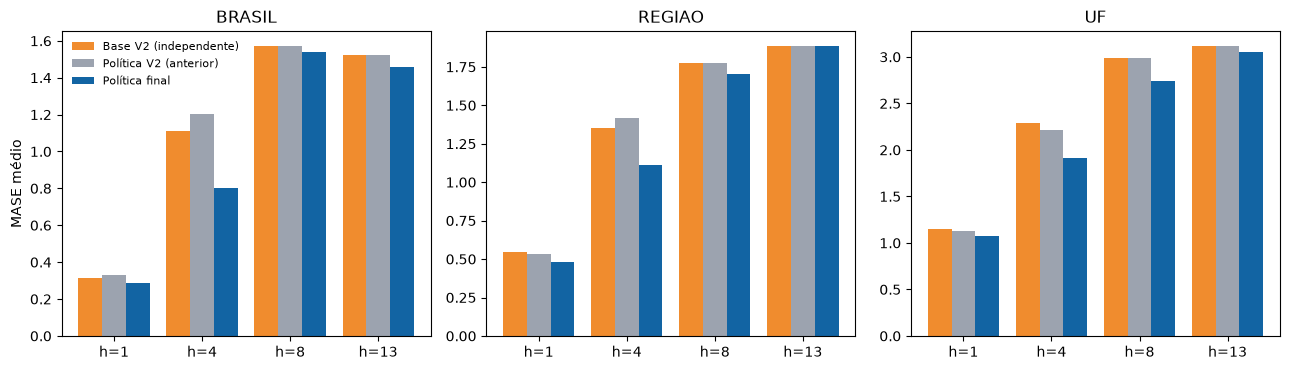

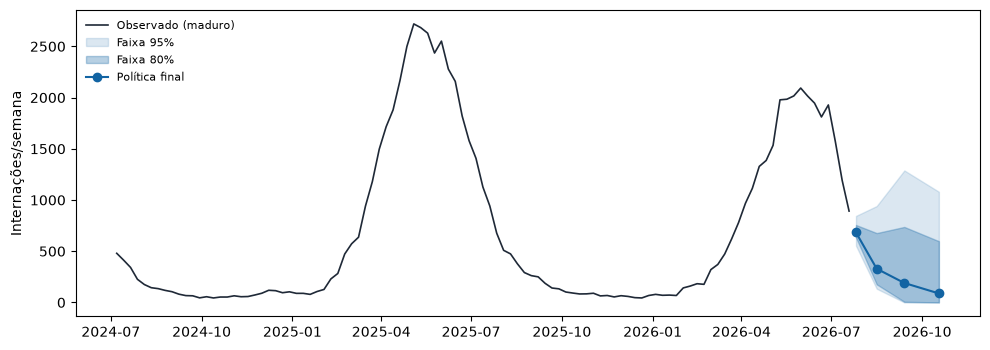

In [8]:
fig, eixos = plt.subplots(1, 3, figsize=(13, 3.8))
x = np.arange(len(HORIZONTES))
for eixo, nivel in zip(eixos, ORDEM_NIVEL):
    d = desempenho[desempenho["nivel"] == nivel].sort_values("horizonte_semanas")
    for k, (coluna, rotulo, cor) in enumerate([("mase_base_v2", "Base V2 (independente)", "#f08c2e"),
                                               ("mase_politica_v2", "Política V2 (anterior)", "#9ca3af"),
                                               ("mase_politica_final", "Política final", "#1264a3")]):
        eixo.bar(x + (k - 1) * 0.27, d[coluna], 0.27, label=rotulo, color=cor)
    eixo.set_xticks(x, [f"h={h}" for h in HORIZONTES])
    eixo.set_title(nivel)
eixos[0].set_ylabel("MASE médio")
eixos[0].legend(fontsize=8, frameon=False)
fig.tight_layout()
fig.savefig(DIR_SAIDA / "comparacao_mase_politica_final.png", dpi=150)
plt.show()

brasil = intervalos[intervalos["nivel"] == "BRASIL"].sort_values("data_alvo")
observado = Y.loc["2024-07-01":, "BRASIL_BRASIL"]
fig, eixo = plt.subplots(figsize=(10, 3.6))
eixo.plot(observado.index, observado.values, color="#1f2937", lw=1.2, label="Observado (maduro)")
eixo.fill_between(brasil["data_alvo"], brasil["limite_inferior_95"], brasil["limite_superior_95"], color="#1264a3",
                  alpha=0.15, label="Faixa 95%")
eixo.fill_between(brasil["data_alvo"], brasil["limite_inferior_80"], brasil["limite_superior_80"], color="#1264a3",
                  alpha=0.3, label="Faixa 80%")
eixo.plot(brasil["data_alvo"], brasil["previsao_final"], "o-", color="#1264a3", label="Política final")
eixo.set_ylabel("Internações/semana")
eixo.legend(frameon=False, fontsize=8, loc="upper left")
fig.tight_layout()
fig.savefig(DIR_SAIDA / "previsao_operacional_final_brasil.png", dpi=150)
plt.show()